# UNIVERSIDAD TÉCNICA PARTICULAR DE LOJA (UTPL)
## Interoperabilidad y Explotación de Datos en Ecosistemas Heterogéneos
**Docente:** Dra. Janneth Alexandra Chicaiza Espinosa
**Integrantes:** Alex Gutiérrez, David Manotoa
**Fecha:** 25 de noviembre de 2026

---
# Entregable 3: Generación de datos RDF
**Dominio:** Smart City Barcelona — movilidad (CityBikes / Bicing) y calidad del aire (Open-Meteo / CAMS).

## 1. Objetivo y flujo de trabajo

Convertir los datos extraídos y limpiados en el Entregable 2 a **RDF (Turtle)**, siguiendo el modelo
validado (`E2_extraccion/modelo/vocab.ttl` y `modelo_datos.png`), para luego almacenarlos en **GraphDB**.

| Paso | Qué se hace | Código |
|---|---|---|
| 1 | Configuración y prefijos del modelo | `generar_rdf.PREFIJOS` |
| 2 | Revisión de los datos de entrada (nulos, duplicados) | `pandas` |
| 3 | Preprocesamiento: corrección de las celdas CAMS | `preprocesar.py` |
| 4 | Esquema de identificación de URIs | `normalizar`, `uri_*` |
| 5 | Prueba con 2 filas | `ejecutar(limite=2)` |
| 6 | Generación Fuente 1 (Bicing) y Fuente 2 (CAMS) | `generar_bicing`, `generar_calidad_aire` |
| 7 | Validación contra el modelo | `validar` |
| 8 | Serialización y totales por clase | `serialize`, SPARQL |
| 9 | Consulta integrada entre fuentes | SPARQL |
| 10 | Almacenamiento en GraphDB | `cargar_graphdb.py` (API REST) |

Toda la lógica está en `E3_rdf/scripts/` (funciones documentadas y probadas con `pytest`);
el notebook la ejecuta paso a paso y muestra el resultado de cada bloque.

## 2. Configuración del entorno

In [1]:
import sys, inspect
from pathlib import Path
from IPython.display import Markdown, display

DIR_E3 = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(DIR_E3 / 'scripts'))

import pandas as pd
import rdflib
import matplotlib.pyplot as plt
import preprocesar
import generar_rdf as gen
import cargar_graphdb

def ver_codigo(funcion):
    """Muestra el código fuente de una función del proyecto dentro del notebook."""
    display(Markdown(f"```python\n{inspect.getsource(funcion)}```"))

print('rdflib', rdflib.__version__, '| pandas', pd.__version__)
print('Datos de entrada:', gen.DIR_PROCESADOS.relative_to(gen.RAIZ))

rdflib 7.6.0 | pandas 3.1.1
Datos de entrada: E2_extraccion/data/processed


## 3. Prefijos del modelo

Antes de crear tripletas se registran los prefijos de **todo** lo que aparece en el modelo:
el de nuestros datos (`data:`), el de nuestro vocabulario (`vocab:`) y los vocabularios reutilizados.
`RDF`, `RDFS`, `XSD` y `DCTERMS` vienen precargados en rdflib; `schema:`, `sosa:` y `geo:` se
definen manualmente con `Namespace`, igual que `data:` y `vocab:`.

> Una sola URI base (`http://example.org/bcn-kg/data/`) para **ambas fuentes**: así los nodos
> comunes (las celdas CAMS) son el mismo nodo en los dos archivos y el grafo queda enlazado.

In [2]:
pd.DataFrame([(p, str(ns)) for p, ns in gen.PREFIJOS.items()], columns=['Prefijo', 'Namespace'])

,Prefijo,Namespace
0,data,http://example.org/bcn-kg/data/
1,vocab,http://example.org/bcn-kg/vocab#
2,schema,https://schema.org/
3,sosa,http://www.w3.org/ns/sosa/
4,geo,http://www.w3.org/2003/01/geo/wgs84_pos#
5,dcterms,http://purl.org/dc/terms/
6,rdfs,http://www.w3.org/2000/01/rdf-schema#
7,xsd,http://www.w3.org/2001/XMLSchema#


Clases y propiedades propias definidas en `vocab.ttl` (el modelo validado en el Entregable 2):

In [3]:
vocab = rdflib.Graph().parse(gen.RUTA_VOCAB)
RDF, RDFS = rdflib.RDF, rdflib.RDFS
filas = []
for p in vocab.subjects(RDF.type, RDF.Property):
    filas.append((p.n3(vocab.namespace_manager),
                  vocab.value(p, RDFS.domain).n3(vocab.namespace_manager),
                  vocab.value(p, RDFS.range).n3(vocab.namespace_manager)))
clases = sorted(c.n3(vocab.namespace_manager) for c in vocab.subjects(RDF.type, RDFS.Class))
print('Clases propias:', ', '.join(clases))
pd.DataFrame(sorted(filas), columns=['Propiedad', 'Dominio', 'Rango'])

Clases propias: vocab:CeldaModelo, vocab:Contaminante, vocab:EstacionBicicleta, vocab:EstadoEstacion, vocab:ObservacionCalidadAire, vocab:RedBicicletas


,Propiedad,Dominio,Rango
0,vocab:anclajesLibres,vocab:EstadoEstacion,xsd:nonNegativeInteger
1,vocab:bicicletasDisponibles,vocab:EstadoEstacion,xsd:nonNegativeInteger
2,vocab:bicicletasElectricas,vocab:EstadoEstacion,xsd:nonNegativeInteger
3,vocab:bicicletasMecanicas,vocab:EstadoEstacion,xsd:nonNegativeInteger
4,vocab:contenidaEnCelda,vocab:EstacionBicicleta,vocab:CeldaModelo
5,vocab:distanciaACentroideKm,vocab:EstacionBicicleta,xsd:decimal
6,vocab:enLinea,vocab:EstadoEstacion,xsd:boolean
7,vocab:mideContaminante,vocab:ObservacionCalidadAire,vocab:Contaminante
8,vocab:operadaPor,vocab:RedBicicletas,schema:Organization
9,vocab:perteneceARed,vocab:EstacionBicicleta,vocab:RedBicicletas


## 4. Revisión de los datos de entrada

Se revisan los CSV limpios del Entregable 2: número de filas, duplicados por clave y valores nulos.

In [4]:
claves = {
    'citybikes_estaciones': ['id_estacion'],
    'citybikes_estado': ['id_estacion', 'captura_utc'],
    'citybikes_operadores': ['id_operador'],
    'openmeteo_observaciones': ['id_celda', 'hora_utc', 'contaminante'],
}
resumen = []
for nombre, clave in claves.items():
    df = pd.read_csv(gen.DIR_PROCESADOS / f'{nombre}.csv')
    resumen.append({'archivo': nombre, 'filas': len(df),
                    'duplicados_clave': int(df.duplicated(clave).sum()),
                    'celdas_nulas': int(df.isna().sum().sum())})
pd.DataFrame(resumen)

,archivo,filas,duplicados_clave,celdas_nulas
0,citybikes_estaciones,542,0,0
1,citybikes_estado,542,0,0
2,citybikes_operadores,3,0,0
3,openmeteo_observaciones,288,0,0


## 5. Preprocesamiento: corrección de las celdas CAMS

Al revisar los datos se detectó un problema heredado del Entregable 2: **las dos celdas tenían
exactamente los mismos valores de contaminación**. La causa es que Open-Meteo devuelve en
`latitude`/`longitude` una coordenada **redondeada** (41.4, 2.2) que no identifica la celda real.
Se pidieron 6 puntos; 5 respondieron "41.4, 2.2", pero con **3 series distintas**. Al usar esa
coordenada como identificador se fusionaron celdas diferentes y se perdieron 2 series.

In [5]:
import json
ruta_raw = sorted(preprocesar.DIR_RAW_CAMS.glob('*.json'))[-1]
sobre = json.loads(ruta_raw.read_text(encoding='utf-8'))
filas = []
for (lat, lon), item in zip(preprocesar.puntos_solicitados(sobre['url']), sobre['payload']):
    filas.append({'lat_pedida': lat, 'lon_pedida': lon,
                  'lat_reportada': item['latitude'], 'lon_reportada': item['longitude'],
                  'NO2_primeras_3h': item['hourly']['nitrogen_dioxide'][:3],
                  'celda_real': preprocesar.celda_de(lat, lon)[0]})
pd.DataFrame(filas)

,lat_pedida,lon_pedida,lat_reportada,lon_reportada,NO2_primeras_3h,celda_real
0,41.3865,2.1694,41.4,2.200001,"[38.2, 34.9, 31.6]",celda_41.35_2.15
1,41.4055,2.1623,41.4,2.200001,"[47.3, 38.6, 33.1]",celda_41.45_2.15
2,41.3750,2.1400,41.4,2.100000,"[38.2, 34.9, 31.6]",celda_41.35_2.15
3,41.4260,2.1850,41.4,2.200001,"[47.3, 38.6, 33.1]",celda_41.45_2.15
4,41.3980,2.2030,41.4,2.200001,"[29.5, 30.2, 25.6]",celda_41.35_2.25
5,41.3800,2.1900,41.4,2.200001,"[38.2, 34.9, 31.6]",celda_41.35_2.15


**Solución.** La rejilla CAMS Europa es de 0.1° con centros en múltiplos de 0.05. La celda real
se obtiene con `floor(coordenada × 10) / 10` sobre la coordenada **pedida**. La tabla anterior lo
confirma: los puntos con la misma `celda_real` traen exactamente la misma serie. La función
`desanidar_cams` lo **verifica** y falla si no se cumple. Las estaciones se asignan a su celda con
la misma regla (contención exacta, en lugar de "celda más cercana").

In [6]:
ver_codigo(preprocesar.celda_de)
ver_codigo(preprocesar.desanidar_cams)

```python
def celda_de(lat: float, lon: float) -> tuple[str, float, float]:
    """Devuelve (id_celda, lat_centro, lon_centro) de la celda CAMS de 0.1° que contiene el punto."""
    lat0 = math.floor(round(lat / TAMANO_CELDA, 9)) * TAMANO_CELDA
    lon0 = math.floor(round(lon / TAMANO_CELDA, 9)) * TAMANO_CELDA
    lat_c, lon_c = round(lat0 + TAMANO_CELDA / 2, 2), round(lon0 + TAMANO_CELDA / 2, 2)
    return f"celda_{lat_c:.2f}_{lon_c:.2f}", lat_c, lon_c
```

```python
def desanidar_cams(ruta_raw: Path) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Convierte la captura cruda de Open-Meteo en celdas y observaciones atómicas.

    Agrupa los puntos por celda real y comprueba que sus series coinciden.
    """
    sobre = json.loads(ruta_raw.read_text(encoding="utf-8"))
    items = sobre["payload"] if isinstance(sobre["payload"], list) else [sobre["payload"]]
    puntos = puntos_solicitados(sobre["url"])
    if len(puntos) != len(items):
        raise ValueError(f"{len(puntos)} puntos solicitados pero {len(items)} respuestas")

    series: dict[str, dict] = {}
    celdas: dict[str, dict] = {}
    for (lat, lon), item in zip(puntos, items):
        id_celda, lat_c, lon_c = celda_de(lat, lon)
        serie = {k: item["hourly"][k] for k in ["time", *CONTAMINANTES]}
        if id_celda in series:
            if series[id_celda] != serie:
                raise ValueError(f"Puntos de {id_celda} con series distintas: rejilla incorrecta")
            celdas[id_celda]["puntos_muestreo"] += 1
            continue
        series[id_celda] = serie
        celdas[id_celda] = {"id_celda": id_celda, "latitud_celda": lat_c, "longitud_celda": lon_c,
                            "elevacion": float(item.get("elevation", 0.0)), "puntos_muestreo": 1,
                            "unidad": item.get("hourly_units", {})}

    filas = []
    for id_celda, serie in series.items():
        unidades = celdas[id_celda].pop("unidad")
        for i, t in enumerate(serie["time"]):
            hora = pd.Timestamp(t).tz_localize("UTC").isoformat()
            for var, codigo in CONTAMINANTES.items():
                valor = serie[var][i]
                filas.append({"id_celda": id_celda, "hora_utc": hora, "contaminante": codigo,
                              "valor": None if valor is None else float(valor),
                              "unidad": unidades.get(var, "μg/m³")})
    return pd.DataFrame(list(celdas.values())), pd.DataFrame(filas)
```

In [7]:
pre = preprocesar.ejecutar(guardar=True)
print('Celdas resultantes:')
display(pre['celdas_cams'])
print('Estaciones por celda:')
display(pre['enlace_estacion_celda'].groupby(['id_celda', 'celda_con_datos']).size().rename('estaciones').reset_index())
print('Observaciones CAMS:', len(pre['observaciones_cams']), '(3 celdas × 48 horas × 3 contaminantes)')

Celdas resultantes:


,id_celda,latitud_celda,longitud_celda,elevacion,puntos_muestreo
0,celda_41.35_2.15,41.35,2.15,24.0,3
1,celda_41.35_2.25,41.35,2.25,6.0,1
2,celda_41.45_2.15,41.45,2.15,66.0,2
3,celda_41.45_2.25,41.45,2.25,None,0


Estaciones por celda:


,id_celda,celda_con_datos,estaciones
0,celda_41.35_2.15,True,301
1,celda_41.35_2.25,True,6
2,celda_41.45_2.15,True,193
3,celda_41.45_2.25,False,42


Observaciones CAMS: 432 (3 celdas × 48 horas × 3 contaminantes)


**Limitación documentada:** la celda `celda_41.45_2.25` (noreste, 42 estaciones) no fue muestreada en la
captura del Entregable 2. Se crea igualmente como nodo `vocab:CeldaModelo` para que sus estaciones queden
enlazadas, pero no tiene observaciones. Una nueva captura que incluya un punto en esa celda la completaría.

## 6. Esquema de identificación de URIs

Se usa el **nombre o identificador natural** de cada entidad para formar su URI, con dos reglas de formato
(función `normalizar`): quitar tildes y caracteres especiales, y reemplazar espacios por `_`.
La misma función se usa en las dos fuentes, por eso el nodo común se genera idéntico.

| Clase | Patrón de URI | Ejemplo |
|---|---|---|
| `vocab:RedBicicletas` | `data:red_bicing` | `data:red_bicing` |
| `schema:Organization` | `data:organizacion_<nombre>` | `data:organizacion_CESPA` |
| `vocab:EstacionBicicleta` | `data:estacion_<id>` | `data:estacion_00028670…` |
| `vocab:EstadoEstacion` | `data:estado_<id>_<fecha>` | `data:estado_00028670…_20261112T163024` |
| `vocab:CeldaModelo` | `data:celda_<lat>_<lon>` | `data:celda_41.35_2.15` |
| `vocab:Contaminante` | `data:contaminante_<código>` | `data:contaminante_NO2` (igual que en `vocab.ttl`) |
| `vocab:ObservacionCalidadAire` | `data:obs_<celda>_<hora>_<código>` | `data:obs_celda_41.35_2.15_20261111T000000_NO2` |
| `schema:QuantitativeValue` | `data:resultado_<…>` | `data:resultado_celda_41.35_2.15_…` |
| `schema:Place` | `data:Barcelona` | `data:Barcelona` |

Para las estaciones se usa el `id` de CityBikes y no el nombre, porque los nombres de calle se repiten
(mismo problema que dos personas con el mismo nombre).

In [8]:
ver_codigo(gen.normalizar)
for texto in ['Barcelona de Serveis Municipals, S.A. (BSM)', 'PL  JOANIC - C / BRUNIQUER, 59', 'Universidad Autónoma']:
    print(f'{texto!r:50} -> {gen.normalizar(texto)}')
print(gen.uri_operador('CESPA'))
print(gen.uri_contaminante('PM2_5'))

```python
def normalizar(texto: str) -> str:
    """Formatea un texto para usarlo como nombre local de una URI.

    Quita tildes y diacríticos, reemplaza espacios y símbolos por '_' y
    elimina guiones bajos sobrantes. Es la MISMA regla para ambas fuentes.
    Ejemplo: 'Barcelona de Serveis Municipals, S.A. (BSM)'
             -> 'Barcelona_de_Serveis_Municipals_S.A._BSM'
    """
    ascii_ = unicodedata.normalize("NFKD", str(texto)).encode("ascii", "ignore").decode()
    return re.sub(r"[^A-Za-z0-9._-]+", "_", ascii_).strip("_")
```

'Barcelona de Serveis Municipals, S.A. (BSM)'      -> Barcelona_de_Serveis_Municipals_S.A._BSM
'PL  JOANIC - C / BRUNIQUER, 59'                   -> PL_JOANIC_-_C_BRUNIQUER_59
'Universidad Autónoma'                             -> Universidad_Autonoma
http://example.org/bcn-kg/data/organizacion_CESPA
http://example.org/bcn-kg/data/contaminante_PM2_5


## 7. Prueba con 2 filas

Antes de procesar todo se generan los datos con **solo 2 estaciones y 2 observaciones**, para revisar a mano
que cada tripleta sea coherente con el modelo.

In [9]:
g_b2, g_a2 = gen.ejecutar(limite=2, guardar=False)
print(f'Bicing: {len(g_b2)} tripletas | Calidad del aire: {len(g_a2)} tripletas')
muestra = gen.nuevo_grafo()
estacion = next(g_b2.subjects(rdflib.RDF.type, gen.VOCAB.EstacionBicicleta))
for t in g_b2.triples((estacion, None, None)):
    muestra.add(t)
estado = g_b2.value(estacion, gen.VOCAB.tieneEstado)
for t in g_b2.triples((estado, None, None)):
    muestra.add(t)
print(muestra.serialize(format='turtle'))

Bicing: 54 tripletas | Calidad del aire: 65 tripletas
@prefix data: <http://example.org/bcn-kg/data/> .
@prefix geo: <http://www.w3.org/2003/01/geo/wgs84_pos#> .
@prefix schema: <https://schema.org/> .
@prefix sosa: <http://www.w3.org/ns/sosa/> .
@prefix vocab: <http://example.org/bcn-kg/vocab#> .
@prefix xsd: <http://www.w3.org/2001/XMLSchema#> .

data:estacion_00028670e3d01438515caba403ffd680 a vocab:EstacionBicicleta ;
    vocab:contenidaEnCelda data:celda_41.45_2.15 ;
    vocab:distanciaACentroideKm 5.0504 ;
    vocab:perteneceARed data:red_bicing ;
    vocab:tieneEstado data:estado_00028670e3d01438515caba403ffd680_20261112T163024 ;
    geo:lat 41.4055198 ;
    geo:long 2.1622548 ;
    schema:identifier "106" ;
    schema:name "PL JOANIC - C / BRUNIQUER, 59" .

data:estado_00028670e3d01438515caba403ffd680_20261112T163024 a vocab:EstadoEstacion ;
    vocab:anclajesLibres "5"^^xsd:nonNegativeInteger ;
    vocab:bicicletasDisponibles "1"^^xsd:nonNegativeInteger ;
    vocab:bicicletasE

## 8. Generación de la Fuente 1 — CityBikes (Bicing)

`generar_bicing` recorre los DataFrames y, por cada entidad: (1) forma la URI, (2) la vincula a su clase con
`rdf:type`, (3) añade sus atributos como `Literal` con su tipo XSD y (4) la conecta con las demás entidades.
La estación se conecta con la celda CAMS mediante `vocab:contenidaEnCelda`: ese es el **nodo puente** con la Fuente 2.

In [10]:
ver_codigo(gen.generar_bicing)

```python
def generar_bicing(dfs: dict[str, pd.DataFrame]) -> Graph:
    """Instancia RedBicicletas, Organization, EstacionBicicleta y EstadoEstacion."""
    g = nuevo_grafo()
    url, _ = url_y_fecha(dfs["procedencia"], "citybikes")

    red = uri_red()
    g.add((red, RDF.type, VOCAB.RedBicicletas))
    g.add((red, SCHEMA.identifier, Literal("bicing")))
    g.add((red, SCHEMA.name, Literal("Bicing")))
    g.add((red, DCTERMS.spatial, Literal("Barcelona")))
    g.add((red, SCHEMA.url, Literal(url, datatype=XSD.anyURI)))

    for op in dfs["citybikes_operadores"].itertuples():
        u = uri_operador(op.nombre)
        g.add((u, RDF.type, SCHEMA.Organization))
        g.add((u, SCHEMA.identifier, Literal(normalizar(op.nombre))))
        g.add((u, SCHEMA.name, Literal(op.nombre)))
        g.add((u, SCHEMA.address, Literal("Barcelona, ES")))
        g.add((red, VOCAB.operadaPor, u))

    enlace = dfs["enlace_estacion_celda"].set_index("id_estacion")
    for est in dfs["citybikes_estaciones"].itertuples():
        u = uri_estacion(est.id_estacion)
        g.add((u, RDF.type, VOCAB.EstacionBicicleta))
        g.add((u, SCHEMA.identifier, Literal(str(est.uid))))
        g.add((u, SCHEMA.name, Literal(est.nombre_limpio)))
        g.add((u, GEO.lat, decimal(est.latitud)))
        g.add((u, GEO.long, decimal(est.longitud)))
        g.add((u, VOCAB.perteneceARed, red))
        if est.id_estacion in enlace.index:
            fila = enlace.loc[est.id_estacion]
            # Nodo puente con la Fuente 2: misma URI de celda que en calidad_aire.ttl
            g.add((u, VOCAB.contenidaEnCelda, uri_celda(fila.id_celda)))
            g.add((u, VOCAB.distanciaACentroideKm, decimal(fila.distancia_centro_km)))

    columnas = {
        VOCAB.bicicletasDisponibles: "free_bikes",
        VOCAB.anclajesLibres: "empty_slots",
        VOCAB.bicicletasMecanicas: "normal_bikes",
        VOCAB.bicicletasElectricas: "ebikes",
    }
    for s in dfs["citybikes_estado"].itertuples():
        u = uri_estado(s.id_estacion, s.captura_utc)
        estacion = uri_estacion(s.id_estacion)
        g.add((u, RDF.type, VOCAB.EstadoEstacion))
        g.add((estacion, VOCAB.tieneEstado, u))
        g.add((u, SOSA.hasFeatureOfInterest, estacion))
        g.add((u, SOSA.resultTime, fecha_hora(s.captura_utc)))
        for propiedad, columna in columnas.items():
            valor = getattr(s, columna)
            if pd.notna(valor):
                g.add((u, propiedad, entero(valor)))
        g.add((u, VOCAB.enLinea, Literal(str(s.online).lower() == "true")))
    return g
```

In [11]:
dfs = gen.cargar_csv()
g_bicing = gen.generar_bicing(dfs)
print('Tripletas generadas (Bicing):', len(g_bicing))

Tripletas generadas (Bicing): 9234


## 9. Generación de la Fuente 2 — Open-Meteo (CAMS)

`generar_calidad_aire` crea Barcelona (`schema:Place`), las celdas (contenidas en Barcelona con
`schema:containedInPlace`), los contaminantes y una observación SOSA por celda, hora y contaminante.
Cada observación guarda su valor como `sosa:hasSimpleResult` y como `schema:QuantitativeValue` con su unidad
(`μg/m³`, código UN/CEFACT `GQ`), tal como indica el modelo.

In [12]:
ver_codigo(gen.generar_calidad_aire)

```python
def generar_calidad_aire(dfs: dict[str, pd.DataFrame]) -> Graph:
    """Instancia Place (Barcelona), CeldaModelo, Contaminante,
    ObservacionCalidadAire y su QuantitativeValue."""
    g = nuevo_grafo()
    _, extraido = url_y_fecha(dfs["procedencia"], "openmeteo")

    ciudad = uri_ciudad()
    g.add((ciudad, RDF.type, SCHEMA.Place))
    g.add((ciudad, SCHEMA.name, Literal("Barcelona")))

    for c in dfs["openmeteo_celdas"].itertuples():
        u = uri_celda(c.id_celda)
        g.add((u, RDF.type, VOCAB.CeldaModelo))
        g.add((u, SCHEMA.identifier, Literal(c.id_celda)))
        g.add((u, SCHEMA.name, Literal(f"Celda CAMS Barcelona {c.id_celda.removeprefix('celda_')}")))
        g.add((u, GEO.lat, decimal(c.latitud_celda)))
        g.add((u, GEO.long, decimal(c.longitud_celda)))
        if pd.notna(c.elevacion):
            g.add((u, SCHEMA.elevation, decimal(c.elevacion)))
        g.add((u, DCTERMS.source, Literal("Copernicus CAMS 0.1°")))
        g.add((u, SCHEMA.containedInPlace, ciudad))

    obs = dfs["openmeteo_observaciones"]
    for codigo in sorted(obs.contaminante.unique()):
        u = uri_contaminante(codigo)
        g.add((u, RDF.type, VOCAB.Contaminante))
        g.add((u, DCTERMS.identifier, Literal(codigo)))
        g.add((u, SCHEMA.name, Literal(NOMBRES_CONTAMINANTE.get(codigo, codigo), lang="es")))

    for o in obs.dropna(subset=["valor"]).itertuples():
        u = uri_observacion(o.id_celda, o.hora_utc, o.contaminante)
        r = uri_resultado(u)
        g.add((u, RDF.type, VOCAB.ObservacionCalidadAire))
        g.add((u, DCTERMS.identifier, Literal(str(u).rsplit("/", 1)[-1])))
        g.add((u, SOSA.hasFeatureOfInterest, uri_celda(o.id_celda)))
        g.add((u, VOCAB.mideContaminante, uri_contaminante(o.contaminante)))
        g.add((u, SOSA.resultTime, fecha_hora(o.hora_utc)))
        g.add((u, SOSA.hasSimpleResult, decimal(o.valor)))
        g.add((u, DCTERMS.issued, fecha_hora(extraido)))
        g.add((u, SOSA.hasResult, r))
        g.add((r, RDF.type, SCHEMA.QuantitativeValue))
        g.add((r, SCHEMA.value, decimal(o.valor)))
        g.add((r, SCHEMA.unitText, Literal(o.unidad)))
        g.add((r, SCHEMA.unitCode, Literal("GQ")))  # UN/CEFACT: microgram per cubic metre
        g.add((r, SCHEMA.minValue, decimal("0.0")))
    return g
```

In [13]:
g_aire = gen.generar_calidad_aire(dfs)
print('Tripletas generadas (calidad del aire):', len(g_aire))
obs = next(g_aire.subjects(rdflib.RDF.type, gen.VOCAB.ObservacionCalidadAire))
muestra = gen.nuevo_grafo()
for t in g_aire.triples((obs, None, None)):
    muestra.add(t)
for t in g_aire.triples((g_aire.value(obs, gen.SOSA.hasResult), None, None)):
    muestra.add(t)
print(muestra.serialize(format='turtle'))

Tripletas generadas (calidad del aire): 5658


@prefix data: <http://example.org/bcn-kg/data/> .
@prefix dcterms: <http://purl.org/dc/terms/> .
@prefix schema: <https://schema.org/> .
@prefix sosa: <http://www.w3.org/ns/sosa/> .
@prefix vocab: <http://example.org/bcn-kg/vocab#> .
@prefix xsd: <http://www.w3.org/2001/XMLSchema#> .

data:obs_celda_41.35_2.15_20261111T000000_NO2 a vocab:ObservacionCalidadAire ;
    vocab:mideContaminante data:contaminante_NO2 ;
    dcterms:identifier "obs_celda_41.35_2.15_20261111T000000_NO2" ;
    dcterms:issued "2026-11-12T16:30:54.720986+00:00"^^xsd:dateTime ;
    sosa:hasFeatureOfInterest data:celda_41.35_2.15 ;
    sosa:hasResult data:resultado_celda_41.35_2.15_20261111T000000_NO2 ;
    sosa:hasSimpleResult 38.2 ;
    sosa:resultTime "2026-11-11T00:00:00+00:00"^^xsd:dateTime .

data:resultado_celda_41.35_2.15_20261111T000000_NO2 a schema:QuantitativeValue ;
    schema:minValue 0.0 ;
    schema:unitCode "GQ" ;
    schema:unitText "μg/m³" ;
    schema:value 38.2 .




## 10. Validación contra el modelo

`validar` comprueba automáticamente, sobre los datos + `vocab.ttl`:
1. que cada propiedad `vocab:` respete su `rdfs:domain` y `rdfs:range` (clase o tipo XSD);
2. que todo nodo `data:` usado como objeto esté descrito (tenga `rdf:type`);
3. que ningún sujeto quede sin tipo.

Primero se demuestra que detecta errores con un grafo defectuoso; luego se valida el grafo real.

In [14]:
ver_codigo(gen.validar)

```python
def validar(grafo: Graph, vocab: Graph) -> list[str]:
    """Comprueba la coherencia de los datos con vocab.ttl. Devuelve errores.

    1. Cada uso de una propiedad vocab: respeta su rdfs:domain y rdfs:range.
    2. Ningún nodo data: usado como objeto queda sin rdf:type (sin describir).
    3. Ningún sujeto queda sin rdf:type.
    """
    errores: list[str] = []
    datos = grafo + vocab
    for prop in vocab.subjects(RDF.type, RDF.Property):
        dominio = vocab.value(prop, RDFS.domain)
        rango = vocab.value(prop, RDFS.range)
        for s, o in grafo.subject_objects(prop):
            if dominio and (s, RDF.type, dominio) not in datos:
                errores.append(f"dominio: {s} {prop} (se esperaba {dominio})")
            if rango is None:
                continue
            if str(rango).startswith(str(XSD)):
                if not isinstance(o, Literal) or (o.datatype or XSD.string) != rango:
                    errores.append(f"rango: {s} {prop} {o!r} (se esperaba {rango})")
            elif (o, RDF.type, rango) not in datos:
                errores.append(f"rango: {s} {prop} {o} (se esperaba {rango})")
    for o in set(grafo.objects()):
        if isinstance(o, URIRef) and str(o).startswith(str(DATA)) and (o, RDF.type, None) not in datos:
            errores.append(f"nodo sin describir: {o}")
    for s in set(grafo.subjects()):
        if (s, RDF.type, None) not in grafo:
            errores.append(f"sujeto sin tipo: {s}")
    return errores
```

In [15]:
malo = rdflib.Graph()
e = gen.DATA['estacion_prueba']
malo.add((e, rdflib.RDF.type, gen.VOCAB.EstacionBicicleta))
malo.add((e, gen.VOCAB.distanciaACentroideKm, rdflib.Literal('lejos')))
malo.add((e, gen.VOCAB.contenidaEnCelda, gen.DATA['celda_que_no_existe']))
print('Grafo defectuoso ->', *gen.validar(malo, vocab), sep='\n  ')

errores = gen.validar(g_bicing + g_aire, vocab)
print(f'\nGrafo del proyecto -> {len(errores)} errores')
celdas_b = set(g_bicing.objects(None, gen.VOCAB.contenidaEnCelda))
celdas_a = set(g_aire.subjects(rdflib.RDF.type, gen.VOCAB.CeldaModelo))
print('Celdas referenciadas desde Bicing que existen en CAMS:', len(celdas_b & celdas_a), 'de', len(celdas_b))

Grafo defectuoso ->
  rango: http://example.org/bcn-kg/data/estacion_prueba http://example.org/bcn-kg/vocab#contenidaEnCelda http://example.org/bcn-kg/data/celda_que_no_existe (se esperaba http://example.org/bcn-kg/vocab#CeldaModelo)
  rango: http://example.org/bcn-kg/data/estacion_prueba http://example.org/bcn-kg/vocab#distanciaACentroideKm rdflib.term.Literal('lejos') (se esperaba http://www.w3.org/2001/XMLSchema#decimal)
  nodo sin describir: http://example.org/bcn-kg/data/celda_que_no_existe



Grafo del proyecto -> 0 errores
Celdas referenciadas desde Bicing que existen en CAMS: 4 de 4


## 11. Serialización y totales de nodos por clase

Se guardan dos archivos Turtle, uno por fuente (`serialize` elige el formato por la extensión). El total de
nodos por clase se calcula con SPARQL; **la misma consulta** (`E3_rdf/sparql/01_nodos_por_clase.rq`) se ejecuta
luego en GraphDB para comprobar que la carga está completa.

In [16]:
gen.ejecutar(guardar=True)
for f in sorted(gen.DIR_SALIDA.glob('*.ttl')):
    n = len(rdflib.Graph().parse(f))
    print(f'{f.name:20} {f.stat().st_size/1024:8.1f} KB  {n:6} tripletas (releído desde disco)')

total = gen.nuevo_grafo()
total += g_bicing
total += g_aire
tabla = gen.nodos_por_clase(total)
print('Total de tripletas de datos:', len(total))
tabla

bicing.ttl              487.4 KB    9234 tripletas (releído desde disco)
calidad_aire.ttl        291.7 KB    5658 tripletas (releído desde disco)
Total de tripletas de datos: 14892


,Clase,Nodos
0,vocab:EstacionBicicleta,542
1,vocab:EstadoEstacion,542
2,vocab:ObservacionCalidadAire,432
3,schema:QuantitativeValue,432
4,vocab:CeldaModelo,4
5,vocab:Contaminante,3
6,schema:Organization,3
7,vocab:RedBicicletas,1
8,schema:Place,1


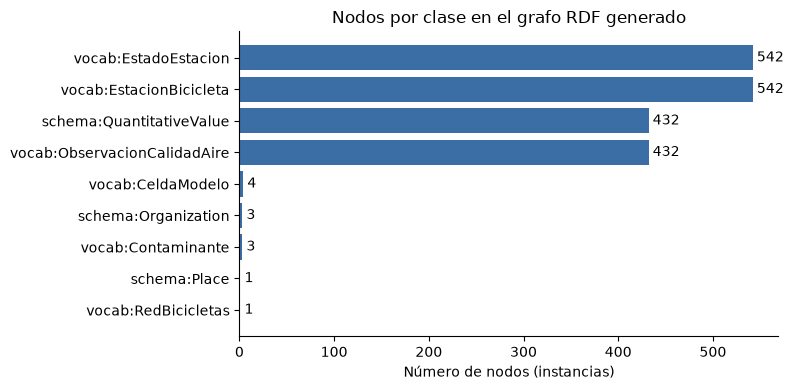

In [17]:
fig, ax = plt.subplots(figsize=(8, 4))
orden = tabla.sort_values('Nodos')
barras = ax.barh(orden['Clase'], orden['Nodos'], color='#3b6ea5')
ax.bar_label(barras, padding=3)
ax.set_xlabel('Número de nodos (instancias)')
ax.set_title('Nodos por clase en el grafo RDF generado')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

## 12. Consulta integrada entre las dos fuentes

La prueba de que las fuentes quedaron **enlazadas**: partiendo de las estaciones (Fuente 1) se llega, a través
de la celda común, a las observaciones de NO₂ (Fuente 2). Consulta guardada en `sparql/03_estacion_aire.rq`.

In [18]:
consulta = DIR_E3 / 'sparql' / '03_estacion_aire.rq'
res = total.query(consulta.read_text(encoding='utf-8'))
pd.DataFrame([(r.celda.n3(total.namespace_manager), int(r.estaciones), float(r.no2_medio)) for r in res],
             columns=['Celda', 'Estaciones', 'NO2 medio (μg/m³)'])

,Celda,Estaciones,NO2 medio (μg/m³)
0,data:celda_41.35_2.25,6,17.57
1,data:celda_41.35_2.15,301,27.68
2,data:celda_41.45_2.15,193,32.05


Ahora cada celda tiene su propio valor medio de NO₂ (con los datos del Entregable 2 las dos celdas daban
el mismo valor, 27.68). La celda `celda_41.45_2.25` no aparece porque no tiene observaciones.

## 13. Almacenamiento en GraphDB

GraphDB 10.8.5 se ejecuta en Docker (`docker run -d --name graphdb-bcn -p 7200:7200 ontotext/graphdb:10.8.5`).
El script `cargar_graphdb.py` usa la API REST de GraphDB para:
1. crear el repositorio `bcn-kg` (ruleset RDFS-Plus Optimized);
2. importar cada archivo en su grafo con nombre: `graph/vocab`, `graph/bicing` y `graph/calidad_aire`;
3. ejecutar las consultas `sparql/01–03` y guardar sus resultados en `E3_rdf/graphdb/`.

In [19]:
ver_codigo(cargar_graphdb.importar)

```python
def importar(base: str) -> None:
    """Sube cada archivo Turtle a su grafo con nombre (contexto)."""
    for grafo, ruta in GRAFOS.items():
        contexto = urllib.parse.quote(f"<{grafo}>")
        peticion(f"{base}/repositories/{REPO}/statements?context={contexto}", "POST",
                 ruta.read_bytes(), {"Content-Type": "text/turtle"})
        print(f"Importado {ruta.relative_to(RAIZ)} -> <{grafo}>")
```

Resultados devueltos por **GraphDB** (sin inferencia), comparados con los calculados localmente con rdflib en la
sección 11: deben coincidir exactamente.

In [20]:
import json
dir_gdb = DIR_E3 / 'graphdb'
gdb = pd.DataFrame(json.loads((dir_gdb / '01_nodos_por_clase.json').read_text(encoding='utf-8')))
gdb['Clase'] = [total.namespace_manager.normalizeUri(rdflib.URIRef(c)) for c in gdb['clase']]
gdb['Nodos GraphDB'] = gdb['nodos'].astype(int)
comparacion = tabla.merge(gdb[['Clase', 'Nodos GraphDB']], on='Clase', how='outer')
comparacion['Coincide'] = comparacion['Nodos'] == comparacion['Nodos GraphDB']
total_gdb = json.loads((dir_gdb / '02_total_tripletas.json').read_text(encoding='utf-8'))[0]['tripletas']
print('Tripletas explícitas en GraphDB:', total_gdb, '(datos + vocab.ttl)')
comparacion

Tripletas explícitas en GraphDB: 14986 (datos + vocab.ttl)


,Clase,Nodos,Nodos GraphDB,Coincide
0,schema:Organization,3,3,True
1,schema:Place,1,1,True
2,schema:QuantitativeValue,432,432,True
3,vocab:CeldaModelo,4,4,True
4,vocab:Contaminante,3,3,True
5,vocab:EstacionBicicleta,542,542,True
6,vocab:EstadoEstacion,542,542,True
7,vocab:ObservacionCalidadAire,432,432,True
8,vocab:RedBicicletas,1,1,True


Las capturas de GraphDB (grafos importados, totales por clase, jerarquía de clases y visual graph) están en
`E3_rdf/informe/capturas/` y se incluyen en el informe.

## 14. Conclusiones

- Se generaron dos archivos RDF (uno por fuente) bajo una única URI base, enlazados por las celdas CAMS.
- Los datos se validan automáticamente contra el dominio y rango declarados en `vocab.ttl`: 0 errores.
- El preprocesamiento detectó y corrigió una fusión incorrecta de celdas CAMS del Entregable 2, recuperando
  2 series de contaminantes que se habían perdido.
- La prueba con 2 filas, la validación y los tests (`pytest E3_rdf/tests`) permiten regenerar los datos de forma
  reproducible con `python E3_rdf/scripts/generar_rdf.py`.